## Check data by setup

In [1]:
# Setup — run this cell first
import numpy as np                # numpy = fast maths on lists of numbers
import pandas as pd               # pandas = tool for working with tables of data
import matplotlib.pyplot as plt   # matplotlib = tool for drawing charts
import seaborn as sns             # seaborn = prettier chart styling
import warnings                   # lets us hide harmless warning messages

warnings.filterwarnings("ignore")   # hide harmless warnings so output stays clean
pd.set_option("display.max_columns", 20)
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (11, 4.5)

print("✅ Libraries loaded — you're ready to go!")

✅ Libraries loaded — you're ready to go!


## Load the data

The CSV lives in `data/credit_card_fraud_2026.csv` (one folder above this notebook's data directory). Each row is one customer. The column `is_fraud` is the target — 0 means they are cleaned, 1 means they are fraud.

In [2]:
df = pd.read_csv("data/credit_card_fraud_2026.csv")   # read the churn dataset from a CSV file into a table
print(f"Loaded: {len(df):,} rows × {df.shape[1]} columns")
df.head()   # show the first 5 rows

Loaded: 20,000 rows × 26 columns


,transaction_id,amount_usd,merchant_category,card_type,auth_method,channel,device_type,is_foreign_transaction,hours_since_last_txn,txn_count_last_24h,...,ip_country_mismatch,billing_shipping_mismatch,cvv_retry_count,velocity_score,time_of_day_hour,day_of_week,is_ai_generated_scam_attempt,merchant_risk_score,prior_disputes,is_fraud
0,1,42.86,Restaurants,Visa,OTP,Online,Android Phone,False,13.54,2,...,False,False,0,0.1,18,3,False,42.3,0,0
1,2,4.75,Online Retail,Mastercard,3D Secure,Online,Android Phone,False,0.71,2,...,False,False,0,25.8,12,4,False,28.3,0,0
2,3,77.18,Groceries,Mastercard,3D Secure,Online,Mac,False,0.35,5,...,False,True,0,42.3,5,0,False,24.7,1,0
3,4,1.69,Streaming,Visa,No Authentication,POS,Android Phone,False,3.42,6,...,False,False,0,28.9,22,6,False,56.2,1,0
4,5,261.68,Travel,Visa,3D Secure,In-App,iPhone,False,2.43,2,...,False,False,0,3.9,2,4,False,32.7,0,0


## Inspect the data

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 26 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   transaction_id                20000 non-null  int64  
 1   amount_usd                    20000 non-null  float64
 2   merchant_category             20000 non-null  str    
 3   card_type                     20000 non-null  str    
 4   auth_method                   20000 non-null  str    
 5   channel                       20000 non-null  str    
 6   device_type                   20000 non-null  str    
 7   is_foreign_transaction        20000 non-null  bool   
 8   hours_since_last_txn          20000 non-null  float64
 9   txn_count_last_24h            20000 non-null  int64  
 10  distance_from_home_km         20000 non-null  float64
 11  card_age_months               20000 non-null  int64  
 12  customer_age                  20000 non-null  int64  
 13  account_bala

## Notice below:

- **`merchant_category`, `card_type`, `auth_method`, `channel` and `device_type` ` are `string` dtype** — they're text categories. Models can't compute on text directly; we'll need to encode them as numbers (the next notebook).
- **`is_foreign_transaction`, `is_new_merchant`, `used_vpn`, `ip_country_mismatch`, `billing_shipping_mismatch` and `is_ai_generated_scam_attemp` are `boolean`** — Models can't compute on text directly; we'll need to encode them as numbers (the next notebook).
- **Everything else is numeric and complete.**

There is no missing data.

## The class imbalance

Let's see how often `is_fraud == 1`. This number drives every other decision in the project.

Class breakdown:
             count  pct (%)
is_fraud                   
not fraud  19661.0      NaN
fraud        339.0      1.7
no fraud       NaN     98.3


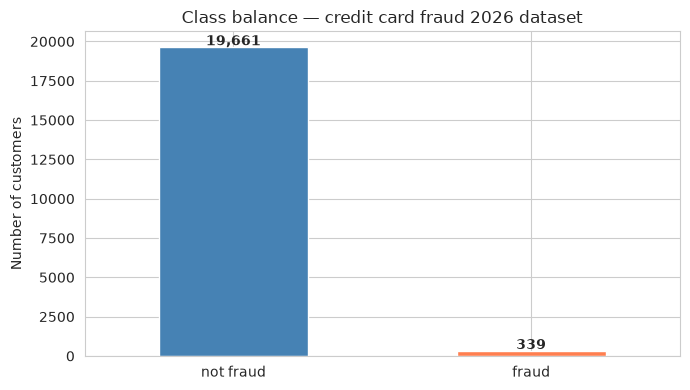

In [4]:
# value_counts() tallies how many customers stayed (0) vs churned (1)
fraud_count = df["is_fraud"].value_counts().rename({0: "not fraud", 1: "fraud"})
fraud_pct   = (df["is_fraud"].value_counts(normalize=True) * 100).round(1).rename({0: "no fraud", 1: "fraud"})

print("Class breakdown:")
print(pd.concat([fraud_count, fraud_pct], axis=1, keys=["count", "pct (%)"]).to_string())

# Draw the counts as a bar chart so the imbalance is visible at a glance
fig, ax = plt.subplots(figsize=(7, 4))
fraud_count.plot(kind="bar", color=["steelblue", "coral"], edgecolor="white", ax=ax)
ax.set_ylabel("Number of customers")
ax.set_xlabel("")
ax.set_title("Class balance — credit card fraud 2026 dataset")
plt.xticks(rotation=0)
for i, v in enumerate(fraud_count):
    ax.text(i, v + 100, f"{v:,}", ha="center", fontweight="bold")
plt.tight_layout()
plt.show()

- About **1.7% of customers are fraud.** That's typical for credit card industry — not absurdly low, but heavily imbalanced.
- **A "model" that always predicts STAYED** would achieve 88% accuracy on this dataset and be totally useless. 

## A first look at one feature

Let's pick a feature where we expect a story — `card_age_months` (how many months the customer has been with credit card). Long term customers should be less likely to fraud credit card.

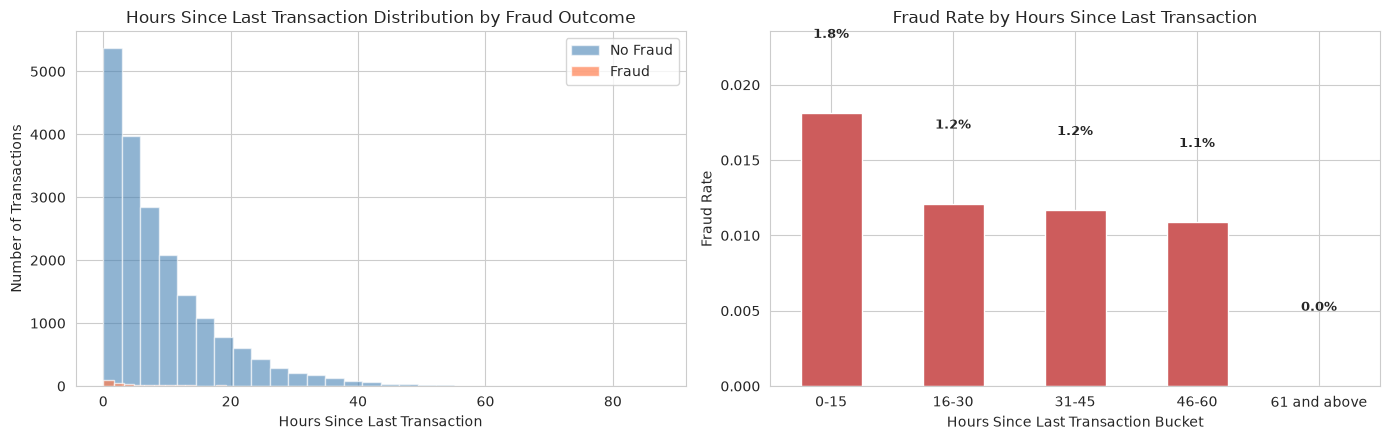

Fraud rate by hours since last transaction bucket:
hours_since_last_txn_bucket
0-15            1.8
16-30           1.2
31-45           1.2
46-60           1.1
61 and above    0.0


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# Left: Histogram of hours since last transaction by fraud class
ax = axes[0]

df[df["is_fraud"] == 0]["hours_since_last_txn"].hist(
    bins=30, alpha=0.6, ax=ax,
    color="steelblue", label="No Fraud"
)

df[df["is_fraud"] == 1]["hours_since_last_txn"].hist(
    bins=30, alpha=0.7, ax=ax,
    color="coral", label="Fraud"
)

ax.set_xlabel("Hours Since Last Transaction")
ax.set_ylabel("Number of Transactions")
ax.set_title("Hours Since Last Transaction Distribution by Fraud Outcome")
ax.legend()

# Right: Fraud rate by hours-since-last-transaction bucket
ax = axes[1]

df["hours_since_last_txn_bucket"] = pd.cut(
    df["hours_since_last_txn"],
    bins=[-0.5, 15, 30, 45, 60, float("inf")],
    labels=["0-15", "16-30", "31-45", "46-60", "61 and above"]
)

fraud_by_hours = (
    df.groupby("hours_since_last_txn_bucket", observed=True)["is_fraud"]
    .mean()
)

fraud_by_hours.plot(
    kind="bar",
    color="indianred",
    edgecolor="white",
    ax=ax
)

ax.set_ylabel("Fraud Rate")
ax.set_xlabel("Hours Since Last Transaction Bucket")
ax.set_title("Fraud Rate by Hours Since Last Transaction")
ax.set_ylim(0, fraud_by_hours.max() * 1.3)

# Display fraud percentages above bars
for i, v in enumerate(fraud_by_hours):
    ax.text(
        i, v + 0.005, f"{v:.1%}",
        ha="center", fontweight="bold", fontsize=9
    )

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Print fraud rates
print("Fraud rate by hours since last transaction bucket:")
print((fraud_by_hours * 100).round(1).to_string())